<a href="https://colab.research.google.com/github/kzlnyi/ML/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%22%D0%9B%D0%A04_%D0%93%D0%BE%D0%BB%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_12_ipynb%22%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
print("Розмір датасету:", df.shape)

Розмір датасету: (205, 26)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [ ]:
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Кількість пропущених значень:")
display(df.isna().sum().sort_values(ascending=False))

print("\nПовні дублікати:", df.duplicated().sum())
print(
    "Дублікати без урахування car_ID:",
    df.drop(columns="car_ID").duplicated().sum()
)

Кількість пропущених значень:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0



Повні дублікати: 0
Дублікати без урахування car_ID: 0


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
df["CarName"].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [ ]:
# car_ID зберігаємо для фінального виведення прогнозів, але не подаємо в модель.
ids = df["car_ID"].copy()

# CarName має дуже високу кардинальність. Для цієї реалізації залишаємо тільки марку автомобіля.
df_model = df.copy()
df_model["brand"] = (
    df_model["CarName"]
    .str.lower()
    .str.split()
    .str[0]
    .replace({
        "maxda": "mazda",
        "porcsche": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen",
    })
)

df_model = df_model.drop(columns=["car_ID", "CarName"])

In [ ]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [ ]:
numeric_initial = df_model.select_dtypes(include=np.number).columns
skew_initial = df_model[numeric_initial].skew().sort_values(key=np.abs, ascending=False)
display(skew_initial.to_frame("skewness"))

,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


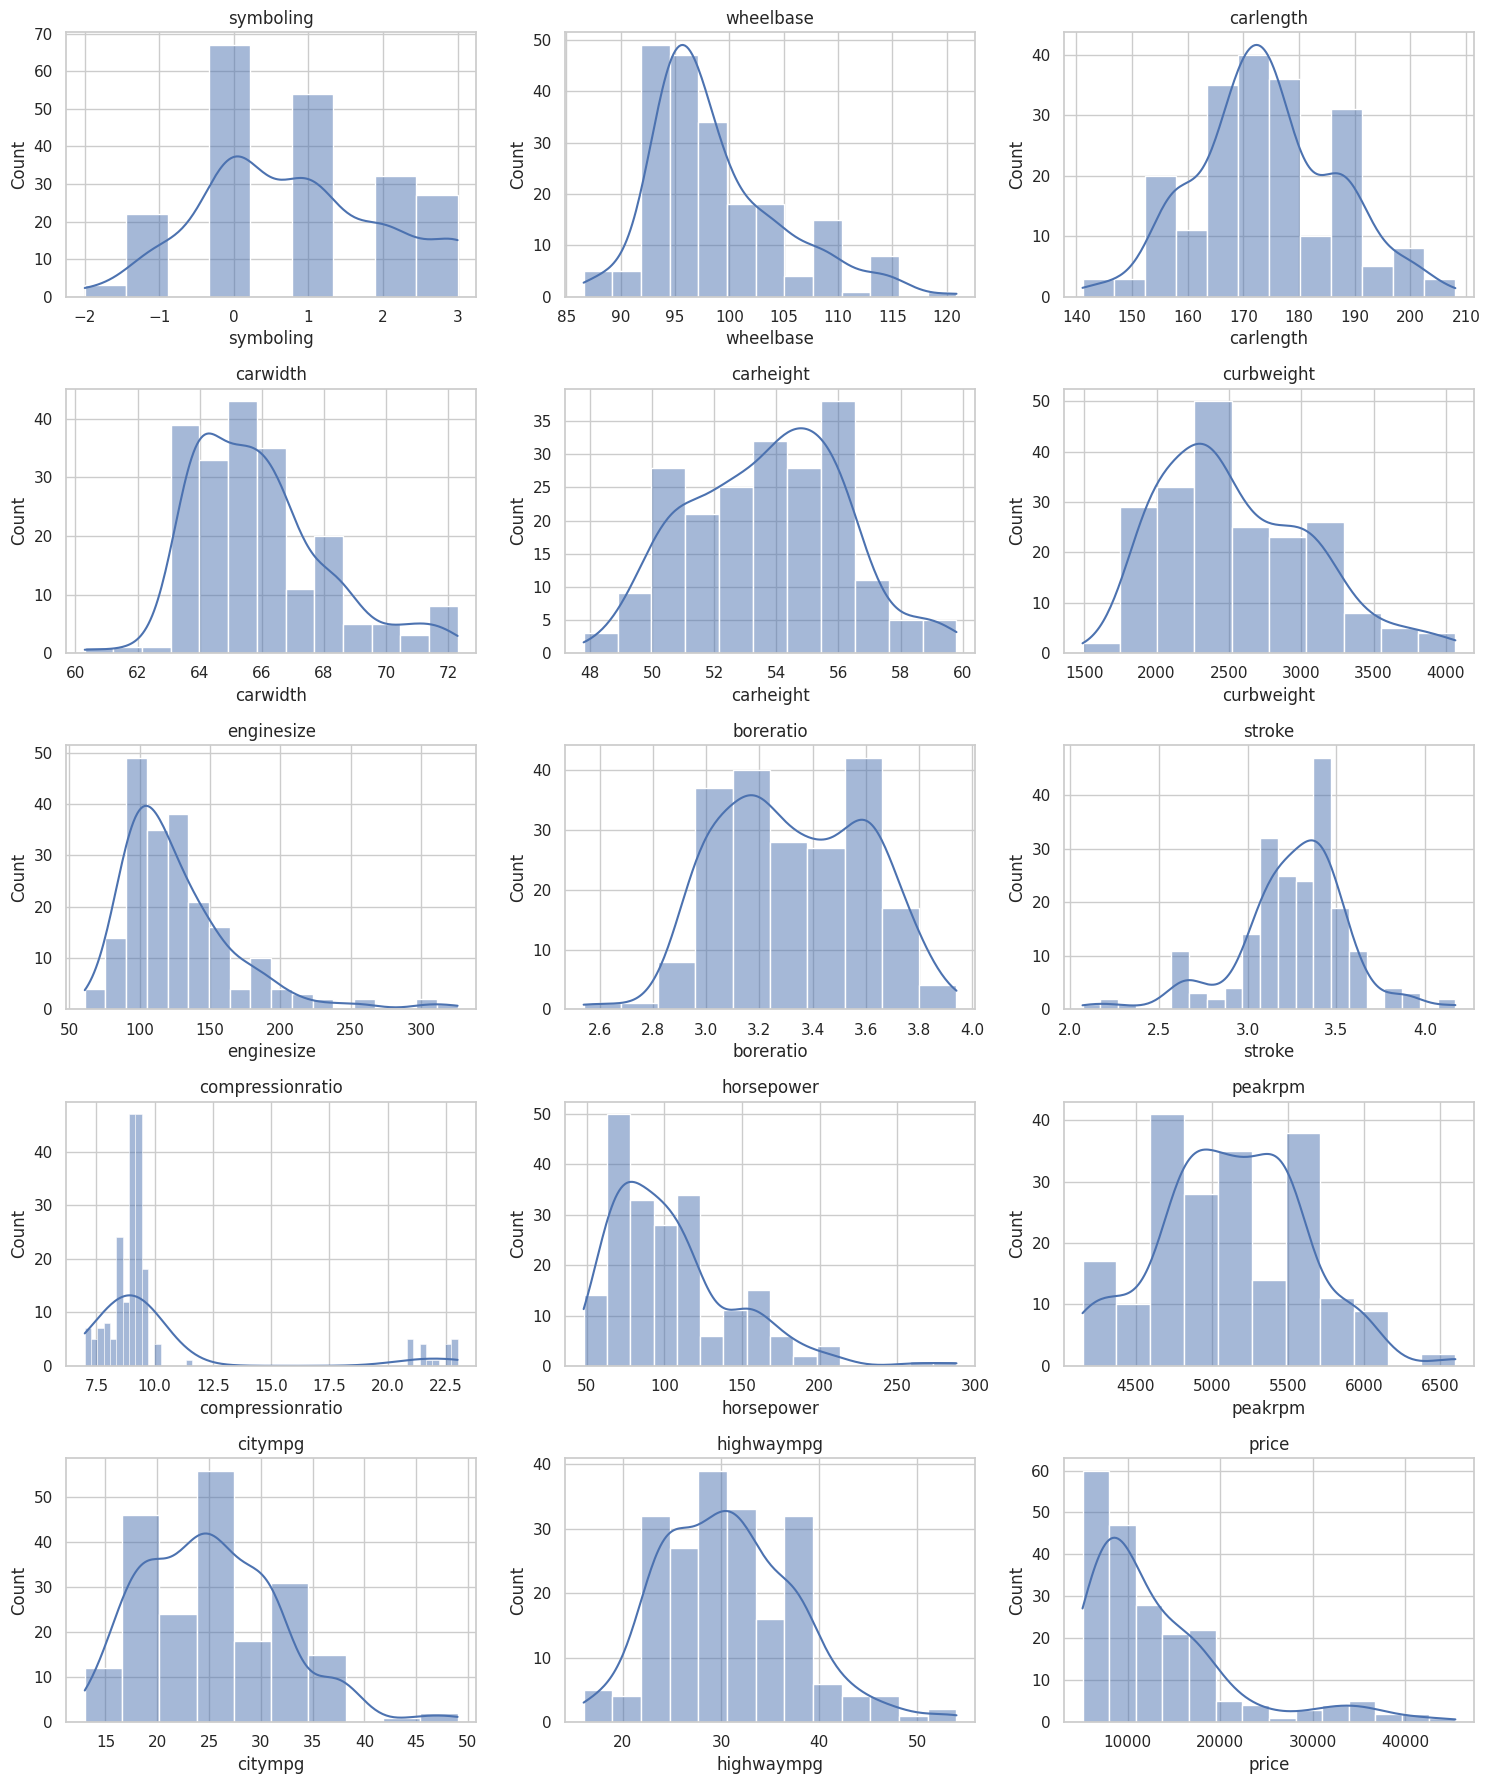

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_initial):
    sns.histplot(df_model[col], kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[len(numeric_initial):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
# Формуємо матрицю ознак X:
# використовуємо всі стовпці, крім цільової змінної price.
X = df_model.drop(columns="price")

# Формуємо цільову змінну y — ціну автомобіля,
# яку надалі будемо прогнозувати.
y = df_model["price"]

# Розділяємо дані на навчальну та тестову вибірки.
#
# 80% даних використовуються для навчання моделей,
# 20% — для оцінювання їхньої якості на нових даних.
#
# random_state=42 забезпечує відтворюваність результату:
# при повторному запуску поділ буде однаковим.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Зберігаємо car_ID для об'єктів, що потрапили
# до навчальної та тестової вибірок.
#
# Індекси беремо безпосередньо з X_train та X_test,
# тому кожен ID залишається пов'язаним із відповідним автомобілем.
#
# car_ID не використовується як ознака для навчання моделі,
# але буде потрібний надалі для ідентифікації автомобілів
# під час аналізу прогнозів.
id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

# Перевіряємо розміри отриманих вибірок:
# кількість рядків і кількість ознак у train та test.
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
# Визначаємо числові ознаки, для яких будемо перевіряти викиди.
# Ознаку symboling не включаємо, оскільки вона має дискретні категоріальні значення.
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

# Обчислюємо межі викидів методом IQR.
# ВАЖЛИВО: усі статистики визначаємо тільки за навчальною вибіркою X_train,
# щоб інформація з тестової вибірки не впливала на підготовку даних.

# Перший квартиль (25-й перцентиль)
q1 = X_train[continuous_cols].quantile(0.25)

# Третій квартиль (75-й перцентиль)
q3 = X_train[continuous_cols].quantile(0.75)

# Міжквартильний розмах
iqr = q3 - q1

# Нижня межа допустимих значень:
# Q1 - 1.5 * IQR
lower_bounds = q1 - 1.5 * iqr

# Верхня межа допустимих значень:
# Q3 + 1.5 * IQR
upper_bounds = q3 + 1.5 * iqr

# Для кожної числової ознаки визначаємо кількість потенційних викидів.
# Значення вважається потенційним викидом, якщо воно:
# 1) менше нижньої межі;
# або
# 2) більше верхньої межі.
outlier_counts = (
    (X_train[continuous_cols].lt(lower_bounds)) |
    (X_train[continuous_cols].gt(upper_bounds))
).sum().sort_values(ascending=False)

# Виводимо кількість потенційних викидів для кожної ознаки.
# Ознаки сортуються від найбільшої кількості викидів до найменшої.
display(outlier_counts.to_frame("potential_outliers_train"))

# Набір даних є відносно невеликим, тому повне видалення рядків із викидами
# може призвести до суттєвої втрати навчальних даних.
# Замість видалення використовуємо обмеження крайніх значень (clipping).

# Створюємо копії вибірок, щоб не змінювати початкові DataFrame.
X_train = X_train.copy()
X_test = X_test.copy()

# У навчальній вибірці:
# - значення, менші за нижню межу, замінюємо нижньою межею;
# - значення, більші за верхню межу, замінюємо верхньою межею.
X_train[continuous_cols] = X_train[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


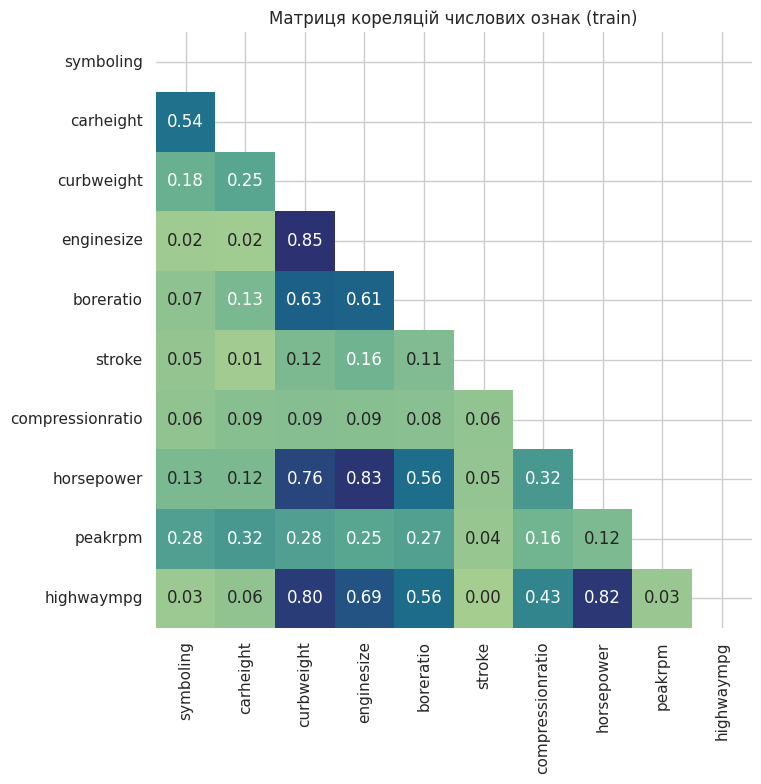

Сильно корельовані пари (|r| > 0.85):
Ознаки для видалення: []


In [ ]:
# Визначаємо числові ознаки у навчальній вибірці.
# Саме для них будемо аналізувати кореляційні зв'язки.
numeric_train_cols = X_train.select_dtypes(include=np.number).columns

# Обчислюємо матрицю попарних кореляцій між числовими ознаками.
# Використовуємо абсолютні значення коефіцієнтів кореляції,
# оскільки нас цікавить сила зв'язку незалежно від його напряму.
corr = X_train[numeric_train_cols].corr().abs()

# Будуємо теплову карту матриці кореляцій.
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    cmap="crest",
    annot=True,     # відображаємо значення коефіцієнтів кореляції
    fmt=".2f",      # округлення до двох знаків після коми
    mask=np.triu(np.ones_like(corr, dtype=bool)),  # приховуємо верхній трикутник
    square=True,
    cbar=False,
)

plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

# Додатково визначаємо кореляцію кожної числової ознаки
# із цільовою змінною price.
#
# Кореляції розраховуються тільки за навчальною вибіркою,
# щоб інформація з тестових даних не впливала на відбір ознак.
target_corr = pd.concat(
    [
        X_train[numeric_train_cols],
        y_train.rename("price")
    ],
    axis=1
).corr(numeric_only=True)["price"].abs()

# Виділяємо верхню частину матриці кореляцій без головної діагоналі.
# Це дає змогу не аналізувати одну й ту саму пару ознак двічі.
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Знаходимо пари ознак із сильною кореляцією.
# У цьому випадку сильною вважаємо кореляцію |r| > 0.85.
pairs = []

for col in upper.columns:
    for row in upper.index[upper[col] > 0.85]:
        pairs.append(
            (row, col, upper.loc[row, col])
        )

# Для кожної сильно корельованої пари визначаємо,
# яку з двох ознак доцільно видалити.
#
# Залишаємо ту ознаку, яка має сильніший зв'язок
# із цільовою змінною price.
features_to_drop = set()

for a, b, r in pairs:

    # Якщо ознака a слабше пов'язана з price,
    # ніж ознака b, видаляємо a.
    if target_corr[a] < target_corr[b]:
        features_to_drop.add(a)

    # Інакше видаляємо ознаку b.
    else:
        features_to_drop.add(b)

# Виводимо всі знайдені пари сильно корельованих ознак
# та відповідні коефіцієнти кореляції.
print("Сильно корельовані пари (|r| > 0.85):")
for a, b, r in pairs:
    print(f"{a} — {b}: {r:.3f}")

# Виводимо перелік ознак, які будуть виключені з моделі.
print("Ознаки для видалення:", sorted(features_to_drop))

# Видаляємо вибрані ознаки з навчальної вибірки.
X_train = X_train.drop(
    columns=list(features_to_drop)
)

# Із тестової вибірки видаляємо ТОЧНО ті самі ознаки.
# Повторно визначати кореляції за X_test не можна,
# оскільки тестова вибірка повинна залишатися незалежною
# від процесу підготовки та відбору ознак.
X_test = X_test.drop(
    columns=list(features_to_drop)
)

# Із тестової вибірки видаляємо ТОЧНО ті самі ознаки.
# Повторно визначати кореляції за X_test не можна,
# оскільки тестова вибірка повинна залишатися незалежною
# від процесу підготовки та відбору ознак.
X_test = X_test.drop(
    columns=list(features_to_drop)
)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
# Визначаємо неперервні числові ознаки.
# Ознаку symboling не включаємо, оскільки вона є дискретною
# порядковою ознакою, а не неперервною величиною.
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

# Виділяємо дискретну числову ознаку symboling окремо.
ordinal_numeric_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c == "symboling"
]

# Визначаємо категоріальні ознаки.
categorical_cols = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

# Pipeline для неперервних числових ознак.
numeric_pipeline = Pipeline(steps=[
    # Перетворення Yeo-Johnson використовується
    # для зменшення асиметрії розподілів.
    #
    # standardize=False, оскільки масштабування
    # виконується окремим кроком StandardScaler.
    ("power", PowerTransformer(
    method="yeo-johnson",
    standardize=False
    )),

# Масштабуємо числові ознаки:
# - середнє значення = 0,
# - стандартне відхилення = 1.
("scaler", StandardScaler()),
])

# Pipeline для дискретної числової ознаки symboling.
# Yeo-Johnson до неї не застосовуємо,
# але масштабуємо для моделей, чутливих до масштабу ознак
# (Linear Regression, Ridge, Lasso, SVR).
ordinal_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
])

# Pipeline для категоріальних ознак.
categorical_pipeline = Pipeline(steps=[

    # One-Hot Encoding перетворює категорії
    # на набір бінарних ознак.
    #
    # handle_unknown="ignore" дозволяє обробляти
    # у test категорії, яких не було в train.
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

# Об'єднуємо всі етапи попередньої обробки.
#
# ВАЖЛИВО:
# усі трансформери надалі навчаються тільки на X_train,
# оскільки preprocessor входить до Pipeline моделі.
preprocessor = ColumnTransformer(
    transformers=[

        # Неперервні числові:
        # 1. Yeo-Johnson — зменшує асиметрію розподілу;
        # 2. StandardScaler — приводить ознаки до єдиного масштабу.
        ("continuous", numeric_pipeline, continuous_cols),

        # Дискретна числова:
        # StandardScaler.
        ("ordinal", ordinal_pipeline, ordinal_numeric_cols),

        # Категоріальні:
        # One-Hot Encoding.
        ("categorical", categorical_pipeline, categorical_cols),
    ],

    # Інші стовпці не передаємо до моделі.
    remainder="drop",

    # Не додаємо префікси continuous__, ordinal__, categorical__
    # до назв ознак.
    verbose_feature_names_out=False,
)

# Перевірка результату PowerTransformer

# Для демонстраційної перевірки використовуємо
# той самий pipeline, що буде застосовуватися у моделях.
#
# clone() створює незалежну копію pipeline,
# тому основний preprocessor ще не навчається.
num_check = clone(numeric_pipeline)

# Навчаємо pipeline тільки на неперервних числових
# ознаках навчальної вибірки.
num_train_transformed = pd.DataFrame(
    num_check.fit_transform(
        X_train[continuous_cols]
    ),
    columns=continuous_cols,
    index=X_train.index,
)

# Перевіряємо асиметрію розподілів після трансформації.
#
# Чим ближче skewness до 0,
# тим більш симетричним є розподіл ознаки.
skewness_after = (
    num_train_transformed
    .skew()
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

display(
    skewness_after.to_frame("skewness_after")
)

,skewness_after
horsepower,0.066280
curbweight,0.049894
enginesize,0.044834
stroke,0.015846
highwaympg,-0.012188
boreratio,-0.005941
carheight,-0.005170
compressionratio,0.004872
peakrpm,-0.003589


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
# Створюємо словник регресійних моделей,
# які будемо навчати та порівнювати між собою.
estimators = {

    # Linear Regression — базова лінійна модель.
    # Оцінює лінійну залежність між ознаками
    # та цільовою змінною price.
    "Linear Regression": LinearRegression(),

    # Ridge Regression — лінійна регресія
    # з L2-регуляризацією.
    #
    # Регуляризація зменшує великі значення коефіцієнтів
    # і може знизити ризик перенавчання.
    #
    # alpha визначає силу регуляризації.
    "Ridge": Ridge(
        alpha=1.0
    ),

    # Lasso Regression — лінійна регресія
    # з L1-регуляризацією.
    #
    # Lasso може зменшувати деякі коефіцієнти до нуля,
    # фактично виконуючи додатковий відбір ознак.
    #
    # max_iter збільшено для забезпечення
    # достатньої кількості ітерацій для збіжності.
    "Lasso": Lasso(
        alpha=1.0,
        max_iter=20000
    ),

    # Random Forest — ансамблева модель,
    # що будує множину дерев рішень
    # та усереднює їхні прогнози.
    #
    # n_estimators=500 — кількість дерев.
    # random_state=42 — відтворюваність результатів.
    # n_jobs=-1 — використання всіх доступних ядер процесора.
    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),

    # Gradient Boosting — ансамблевий метод,
    # у якому дерева будуються послідовно.
    #
    # Кожне наступне дерево намагається
    # скоригувати помилки попередніх.
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
        # Support Vector Regression (SVR) —
    # метод опорних векторів для задачі регресії.
    #
    # SVR є чутливим до масштабу ознак,
    # тому попереднє масштабування числових
    # ознак є особливо важливим.
    "SVR": SVR(),
}
# Для кожної моделі створюємо окремий Pipeline.
#
# Pipeline забезпечує послідовне виконання:
#
# 1. preprocess — попередня обробка ознак:
#
#    неперервні числові ознаки:
#    Yeo-Johnson + StandardScaler;
#
#    symboling:
#    StandardScaler;
#
#    категоріальні ознаки:
#    OneHotEncoder.
#
# 2. model — навчання відповідної
#    регресійної моделі.
#
# ВАЖЛИВО:
# preprocessor навчається тільки під час fit()
# відповідного Pipeline на X_train.
# Тестова вибірка не використовується
# для оцінювання параметрів перетворень.
models = {

    name: Pipeline(steps=[

        # Для кожної моделі створюємо незалежну
        # копію preprocessor.
        ("preprocess", clone(preprocessor)),

        # Після попередньої обробки дані
        # передаються відповідній регресійній моделі.
        ("model", estimator),

    ])

    for name, estimator in estimators.items()
}

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
# Створюємо порожній список для збереження
# результатів оцінювання всіх моделей.
results = []

# Створюємо словник для збереження прогнозів
# кожної моделі на тестовій вибірці.
#
# Він знадобиться надалі для побудови графіків
# та детального аналізу прогнозів.
predictions = {}

# Послідовно навчаємо та оцінюємо кожну модель.
for name, model in models.items():

    # Навчаємо весь Pipeline на навчальній вибірці.
    #
    # Усередині Pipeline спочатку навчається preprocessor:
    # - PowerTransformer;
    # - StandardScaler;
    # - OneHotEncoder.
    #
    # Після цього на підготовлених даних
    # навчається відповідна регресійна модель.
    model.fit(X_train, y_train)

    # Отримуємо прогноз значень price
    # для тестової вибірки.
    y_pred = model.predict(X_test)

        # Зберігаємо прогнози кожної моделі
    # для подальшого аналізу.
    predictions[name] = y_pred

    # Обчислюємо метрики якості моделі
    # ТІЛЬКИ на тестовій вибірці.
    results.append({

        # Назва моделі.
        "Model": name,

        # R² - коефіцієнт детермінації.
        # Показує, яку частину варіації цільової змінної
        # пояснює модель.
        #
        # Чим ближче R² до 1, тим краща модель.
        "R2": r2_score(
            y_test,
            y_pred
        ),
                # MAE — середня абсолютна помилка.
        #
        # Показує середню абсолютну різницю
        # між фактичною та прогнозованою ціною.
        # Вимірюється в тих самих одиницях, що й price.
        #
        # Чим менше MAE, тим краще.
        "MAE": mean_absolute_error(
            y_test,
            y_pred
        ),

        # MSE — середня квадратична помилка.
        #
        # Сильніше штрафує великі помилки,
        # оскільки різниця між фактичним
        # і прогнозованим значенням підноситься до квадрату.
        #
        # Чим менше MSE, тим краще.
        "MSE": mean_squared_error(
            y_test,
            y_pred
        ),
                # MAPE — середня абсолютна відсоткова помилка.
        #
        # Показує, на скільки відсотків у середньому
        # прогноз моделі відрізняється від фактичної ціни.
        #
        # Функція sklearn повертає значення у частках,
        # тому множимо результат на 100.
        #
        # Чим менше MAPE, тим краще.
        "MAPE, %": mean_absolute_percentage_error(
            y_test,
            y_pred
        ) * 100,
    })

# Перетворюємо результати у DataFrame.
#
# Сортуємо моделі за R² від найбільшого
# до найменшого значення.
results_df = (
    pd.DataFrame(results)
    .sort_values(
        "R2",
        ascending=False
    )
    .reset_index(drop=True)
)

# Виводимо підсумкову таблицю
# з результатами всіх моделей.
display(results_df)

,Model,R2,MAE,MSE,"MAPE, %"
0,Random Forest,0.954501,1316.642114,3.591837e+06,9.661980
1,Gradient Boosting,0.932851,1710.913507,5.300997e+06,11.987164
2,Linear Regression,0.883590,2086.675529,9.189877e+06,16.097839
3,Lasso,0.880673,2055.833620,9.420120e+06,14.732989
4,Ridge,0.838921,2548.564743,1.271620e+07,19.712972
5,SVR,-0.100102,5698.293951,8.684648e+07,36.040836


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
# Список для збереження результатів
results = []
predictions = {}

for name, model in models.items():

    # Прогноз
    y_pred = model.predict(X_test)

    # Зберігаємо прогноз
    predictions[name] = y_pred

    # Обчислюємо метрики
    results.append({
        "Model": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": (
            mean_absolute_percentage_error(
                y_test,
                y_pred
            ) * 100
        )
    })

# Створюємо порівняльну таблицю
results_df = (
    pd.DataFrame(results)
    .sort_values(
        "R²",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Порівняння якості регресійних моделей:")
display(results_df)

Порівняння якості регресійних моделей:


,Model,R²,MAE,MSE,"MAPE, %"
0,Random Forest,0.954501,1316.642114,3.591837e+06,9.661980
1,Gradient Boosting,0.932851,1710.913507,5.300997e+06,11.987164
2,Linear Regression,0.883590,2086.675529,9.189877e+06,16.097839
3,Lasso,0.880673,2055.833620,9.420120e+06,14.732989
4,Ridge,0.838921,2548.564743,1.271620e+07,19.712972
5,SVR,-0.100102,5698.293951,8.684648e+07,36.040836


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування price належить до задачі регресії, оскільки ціна автомобіля є неперервним числовим значенням. Logistic Regression не підходить для безпосереднього прогнозування ціни, тому що ця модель використовується для класифікації та визначення ймовірності належності до певного класу, а не для передбачення конкретної вартості. У своїй роботі я використав Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting та SVR, оскільки всі ці моделі призначені для задач регресії та дозволяють прогнозувати числові значення на основі характеристик автомобіля.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


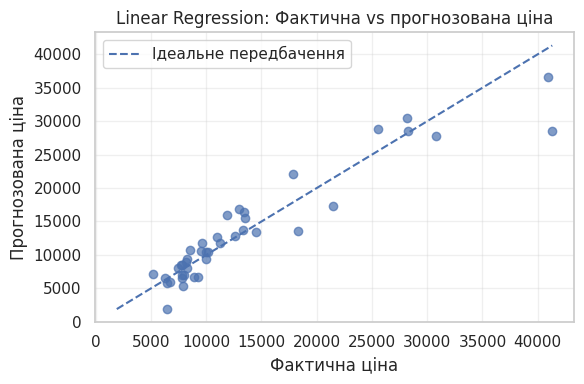

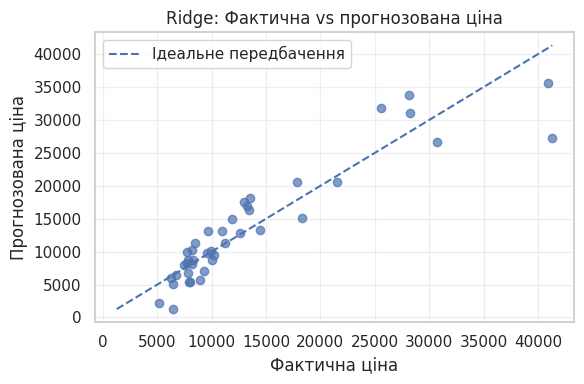

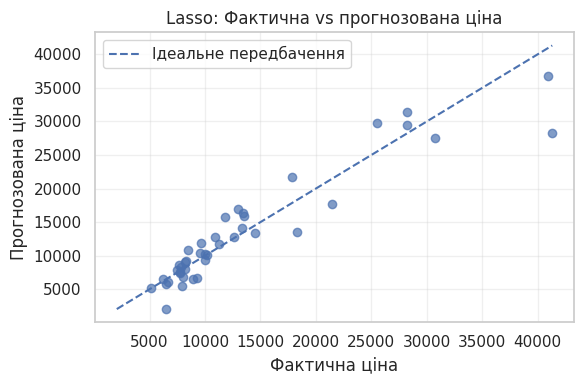

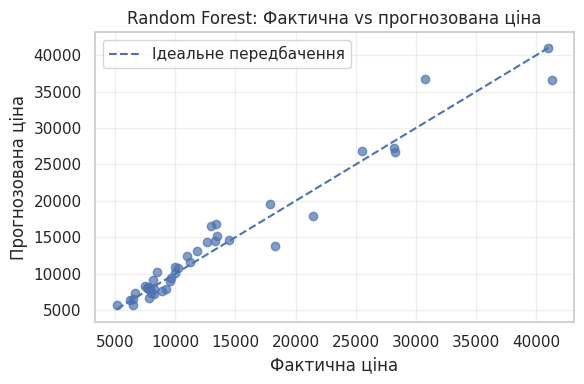

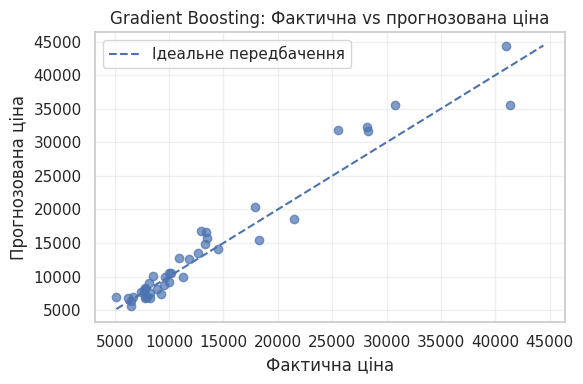

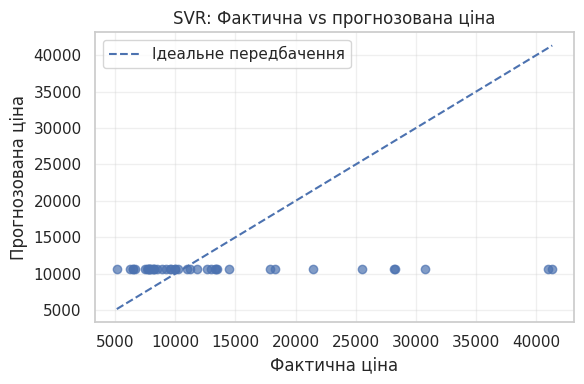

In [ ]:
y_true = y_test.to_numpy()

for name, y_pred in predictions.items():
    y_pred = np.asarray(y_pred).ravel()
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())

    plt.figure(figsize=(6, 4))
    plt.scatter(y_true, y_pred, alpha=0.7)
    plt.plot([lo, hi], [lo, hi], "--", label="Ідеальне передбачення")
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(f"{name}: Фактична vs прогнозована ціна")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
# 10 автомобілів
cars = X_test.sample(10, random_state=42)

# Прогнозуємо ціни
pred = models["Random Forest"].predict(cars)

# Створюємо таблицю
result = pd.DataFrame()

result["car_ID"] = id_test.loc[cars.index]
result["Фактична ціна"] = y_test.loc[cars.index]
result["Прогноз"] = pred

# помилки
result["Помилка"] = abs(result["Фактична ціна"] - result["Прогноз"])
result["Помилка, %"] = result["Помилка"] / result["Фактична ціна"] * 100

# результат
display(result.round(2))

# Аналіз помилок
print("Середня помилка:", result["Помилка"].mean())
print("Середня помилка, %:", result["Помилка, %"].mean())
print("Найбільша помилка:", result["Помилка"].max())
print("Автомобіль з найбільшою помилкою:")

,car_ID,Фактична ціна,Прогноз,Помилка,"Помилка, %"
25,26,6692.0,7298.90,606.90,9.07
175,176,9988.0,10914.13,926.13,9.27
147,148,10198.0,10787.88,589.88,5.78
16,17,41315.0,36648.08,4666.92,11.30
68,69,28248.0,26669.68,1578.32,5.59
146,147,7463.0,8371.82,908.82,12.18
143,144,9960.0,10079.42,119.42,1.20
84,85,14489.0,14659.40,170.40,1.18
194,195,12940.0,16491.07,3551.07,27.44
159,160,7788.0,7879.06,91.06,1.17


Середня помилка: 1320.8933499999998
Середня помилка, %: 8.417369073805755
Найбільша помилка: 4666.923999999999
Автомобіль з найбільшою помилкою:


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


У цій лабораторній роботі я підготував дані та порівняв шість регресійних моделей за метриками R², MAE, MSE і MAPE. Найкращий результат показала модель Random Forest із R² ≈ 0,95 та MAPE ≈ 9,66%, а найгірший — SVR. Попередня обробка даних включала обробку викидів, відбір ознак, зменшення асиметрії, масштабування та кодування категорій. Для перевірки перенавчання можна порівняти результати на навчальній і тестовій вибірках. На основі отриманих результатів я зробив висновок, що Random Forest найкраще підходить для прогнозування цін автомобілів серед досліджених моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
